# MQT DASQA mapper, the shipped five-qubit example: a Quantcore-PDK rebuild, step by step

**Source:** *MQT DASQA* (Designer for Alternative Superconducting Quantum Architectures), Chair for Design Automation,
TU Munich, part of the Munich Quantum Toolkit: <https://github.com/cda-tum/mqt-dasqa> (arXiv:2305.07052), MIT licence
(© 2023 Jagatheesan Jack). Read, never run: the README and its example image `docs/images/4_qubit_2D_square_lattice.png`,
the Metal mapper (`src/mapper/qubit/metal/transmon_pocket_6_qubit.py`, `capacitor/metal/capacitor.py`,
`launchpad/metal/launchpad.py`, `qubit_connector/metal/route_meander_connector.py`,
`qubit_capacitor_connector/metal/qubit_capacitor_connector.py`), the frequency generator
(`src/architecture_generator1/frequency/frequency.py`) and the optimiser (`src/optimizer/metal/optimizer.py`). The rebuild
is distributed under the GPL. Spec: `docs/designs/community/mqt_dasqa.md`.

**What the chip is.** DASQA is a generator, not a fixed chip: a QASM circuit gives a qubit-connectivity profile, the
profile a square-lattice placement and qubit frequencies chosen for yield, and the mapper turns that into a Qiskit Metal
design. Its README image (titled "4 qubit 2D square lattice") shows five qubits in a plus:
- five `TransmonPocket6` pockets on a 3.5 × 3.0 mm grid, orientation −90: `Q_4` in the centre, `Q_3` west, `Q_0` east,
  `Q_2` south, `Q_1` north; connection pads B0 (75 µm), B1 (120), B2 (120), B3 (90) and B4 (90, middle row only), unused
  ones removed;
- four `RouteMeander` buses from the centre to each neighbour (`CS_3_4`, `CU_2_4`, `CU_4_1`, `CS_4_0`), each a λ/2 line
  at the frequency of its first qubit on the generator's silicon stack;
- per qubit a `RoutePathfinder` line from a connection pad to a `CapNInterdigital` series capacitor (`Readout_k`), and a
  line from the capacitor to a `LaunchpadWirebond` (`TL_Readout_k`).

The generator places the centre qubit at 5.17 GHz (the middle of its 5.00–5.34 GHz band) and the others by a Monte-Carlo
yield search. The readout lines are drawn as short paths with no length or frequency (the optimiser's resonator step is
empty), and the qubit geometry is tuned by pickled regression models for f_q.

**This notebook rebuilds the shipped example in the Quantcore PDK; it is not a replica.** What the rebuild keeps and
what it changes:

| topic | source (DASQA example) | this rebuild |
|---|---|---|
| die and frame | a Metal canvas, no chip edge | an 11 × 12 mm die with the Quantcore frame (Designer = source + (2500, 2500) µm, then the core centred), device ID `DASQA-5Q` |
| stack | silicon 750 µm, εr 11.9 (in the bus-length formula) | PDK sapphire 650 µm, εr 10.25 |
| qubits | `TransmonPocket6` with Metal's defaults and the five pad widths | the same cells, options and positions through `metal:TransmonPocket6` |
| qubit frequencies | the yield search in 5.00–5.34 GHz; pocket `pad_gap` / `pad_height` from regression models | **this rebuild's choice** in the same band: `Q_4` 5.17 GHz (the generator's centre value), `Q_0` 5.04, `Q_1` 5.10, `Q_2` 5.24, `Q_3` 5.30 GHz; Quantcore trilayer junctions sized for them, the pockets left at Metal's defaults |
| buses | λ/2 at the first qubit's f_q on silicon (Metal's `guided_wavelength`), 11.28–11.57 mm | **this rebuild's choice**: dispersive λ/2 buses at 6.30 / 6.15 / 6.00 / 5.85 GHz (9.44–10.24 mm), between the qubits and the readouts, drawn as qcc meanders with the source's 99 µm fillet; on sapphire the generator's rule would put them on the qubits (LOM 3) |
| readouts | short `RoutePathfinder` lines, no length | **this rebuild's choice**: λ/2 meanders at 6.6 / 6.8 / 7.0 / 7.2 / 7.4 GHz between the same pad and capacitor |
| launchpads | beside each capacitor; `Q_4`'s and `Q_0`'s sit inside the plus | **PDK pad rule**: all five 100 µm from the die edge; the lines from `Q_4`'s and `Q_0`'s capacitors run out to the west and east edges |
| cheese | none (the output is a live Metal design, no GDS) | the PDK band (`cheese: "auto"`) |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell
with a picture of the chip so far: the die, the five launchpads, the five series capacitors and their pad lines, the
five pocket transmons with junctions sized for the frequency plan, the five readout meanders, the four buses, and then
the whole chip (the sim groups and targets, the centring of the core, the save). Then the same steps as the Flow strip
of the Quantcore KLayout plugin: **Check** (DRC, netlist), **LOM** (simulation and plots), **Simulate** (export to
HFSS, the component simulation, the eigenmode simulation, the full-wave run), **Results** (plots, the values, FEM
against the LOM, a feedback step and the iteration to a target) and **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear.

## Setup

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

This chip's own helpers: `bus_length` is the generator's bus rule (λ_g/2 from Metal's `guided_wavelength` with the
generator's inputs: 10/6 µm CPW, 750 µm silicon, εr 11.9, 200 nm film), kept for comparison (Design 6, LOM 3); `sizing_md` tabulates the junction sizing;
`center_core` centres the chip's core in the die, leaving out the launchpads (pinned to the die edge) and the lines
that run to them.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.circuit.bridges import size_junction, tl_resonator
from quantcore_circuits.layouts.registry import trilayer_junction
from qiskit_metal.analyses.em.cpw_calculations import guided_wavelength

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)


def bus_length(f_GHz):
    """The generator's bus length (µm): λ_g/2 at ``f_GHz`` from Metal's ``guided_wavelength`` with the inputs DASQA's
    ``RouteMeanderConnector`` gives it (10/6 µm CPW, 750 µm substrate, 200 nm film, εr 11.9)."""
    lam = guided_wavelength(f_GHz * 1e9, 10e-6, 6e-6, 750e-6, 200e-9, 11.9)[0]
    return round(float(lam) / 2 * 1e6, 1)


def sizing_md(sizing):
    """Trilayer junction sizing (``circuit.bridges.size_junction``) against the PDK junction rule."""
    rows = ["| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |",
            "|---|---|---|---|---|---|---|"]
    for name, s in sizing.items():
        rows.append(f"| {name} | {s.f_q_GHz:.3f} | {s.c_sigma_fF:.1f} | {s.lj_nH:.2f} | {s.rn_kohm:.1f} | "
                    f"{s.f_q_drawn_GHz:.3f} | {'yes' if s.rn_in_window else 'no'} |")
    return "\n".join(rows)


def center_core(d, skip=(), tol=50.0):
    """Centre the chip's core (every instance and route except ``skip``) in the die: shift the whole design so the
    core's bounding box is centred (pads pinned to an edge keep their edge distance). Returns the shift (µm)."""
    from kqcircuits.pya_resolver import pya
    from quantcore_circuits.assembly.sidecar import sidecar_dict

    side = sidecar_dict(rebuild(d), overlays=False)
    box = pya.DBox()
    for name, inst in side["instances"].items():
        if name not in skip and inst.get("bbox"):
            box += pya.DBox(*inst["bbox"])
    for name, route in side["routes"].items():
        if name not in skip:
            for x, y in route.get("polyline") or []:
                box += pya.DPoint(x, y)
    x0, y0, x1, y1 = d.design.chip.box
    dx, dy = round((x0 + x1) / 2 - box.center().x, 1), round((y0 + y1) / 2 - box.center().y, 1)
    if abs(dx) <= tol and abs(dy) <= tol:
        return (0.0, 0.0)
    translate_design(d, dx, dy)
    return (dx, dy)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. Every rule below is applied by the library, not by this notebook: the frame and
the cheese are drawn by the chip build, the pad rule by `edge=`, the junctions by `trilayer_junction`, and the PDK
design warnings come out of the DRC.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout line, the qubits,
the readouts, the coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of
the chip so far (and, live, KLayout redraws after every cell). Every position is a source coordinate + (2500, 2500) µm
(`P(x, y)`) until the centring in segment 8, so the order changes nothing.

| segment | what is placed here |
|---|---|
| 1 | the 11 × 12 mm die with the Quantcore frame |
| 2 | the five launchpads, moved to the die edge by the PDK pad rule |
| 3 | the readout line: the five `CapNInterdigital` series capacitors and their lines to the pads |
| 4 | qubit placement: five `TransmonPocket6` pockets, trilayer junctions sized for the frequency plan |
| 5 | the five λ/2 readout meanders, 6.6–7.4 GHz |
| 6 | the coupling: the four buses from `Q_4` to its neighbours, dispersive at 5.85–6.30 GHz |
| 7 | control lines: none (the generator draws no drive or flux lines) |
| 8 | the whole chip: the sim groups and targets, the centring of the core, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws its frame round it: the L dicing
markers in the corners (layer 1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the device ID
(`name_chip`) on a free edge. The source has no chip edge: its plus spans 9.1 × 10 mm with the launchpads, so the rebuild
uses an 11 × 12 mm die and maps a source position (µm, centre qubit at (3500, 3000)) onto the die with
`P(x, y) = (x + 2500, y + 2500)`.

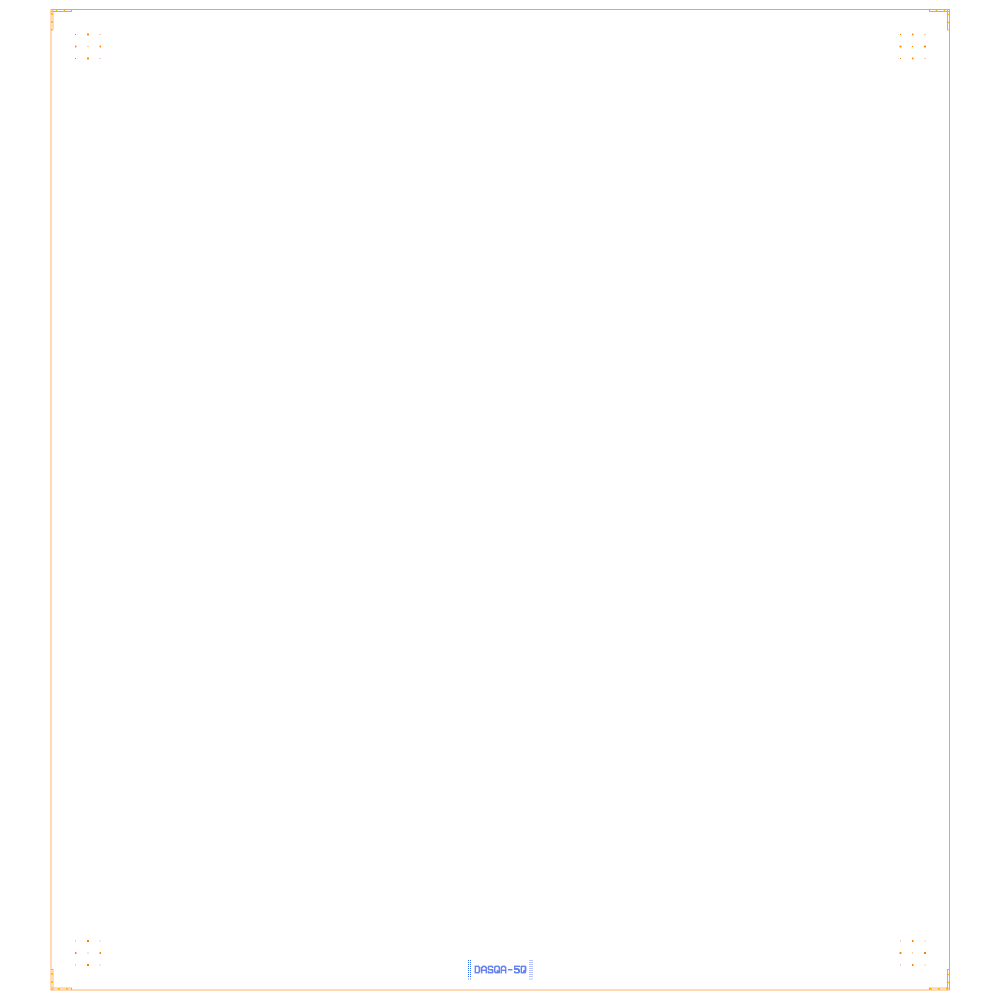

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/mqt_dasqa_die.png')

In [5]:
d = Designer("mqt_dasqa", box=(0, 0, 11000, 12000), chip={"name_chip": "DASQA-5Q"}, live=LIVE)
X0 = Y0 = 2500.0                                 # Designer = source + (2500, 2500) µm until the centring (Design 8)
P = lambda x, y: (X0 + x, Y0 + y)
layout_step(d, OUT / "mqt_dasqa_die.png", size=(1000, 1000), width=360)

## Design 2 · Bond pads: five launchpads and the PDK pad rule

The mapper puts each `LaunchpadWirebond` beside its readout capacitor: 400 µm beyond the capacitor (2000 µm from the
qubit) for the south and north qubits, 300 µm west of it for the three on the middle row. For `Q_3` (west) that is outside the plus, but `Q_4`'s
pad lands between `Q_3` and `Q_4` and `Q_0`'s between `Q_4` and `Q_0`, in the middle of the chip.

The PDK puts every bond pad and launcher with the outer edge of its etch **`frame.pad_edge` = 100 µm from the die
edge**: `edge="n"` / `"s"` / `"e"` / `"w"` slides a pad perpendicular to that edge until that holds and keeps its position
along the edge. So:
- `Q_1`'s and `Q_2`'s pads keep their x and slide to the north and south edges; both are set 25 µm closer to the axis
  (x = 3625 / 3375 in the source frame, against 3650 / 3350) so the pad, the capacitor and the qubit's readout pin are in
  line;
- `Q_3`'s pad keeps its height and slides to the west edge;
- `Q_4`'s pad goes to the west edge at y = 7000 µm (above `Q_3`) and `Q_0`'s to the east edge at y = 4000 µm (below `Q_0`):
  this rebuild's choice of the nearest free stretch of edge. Their capacitor lines (Design 3) run out to them.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| Launch_Readout_0 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| Launch_Readout_1 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| Launch_Readout_2 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_Readout_3 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| Launch_Readout_4 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |

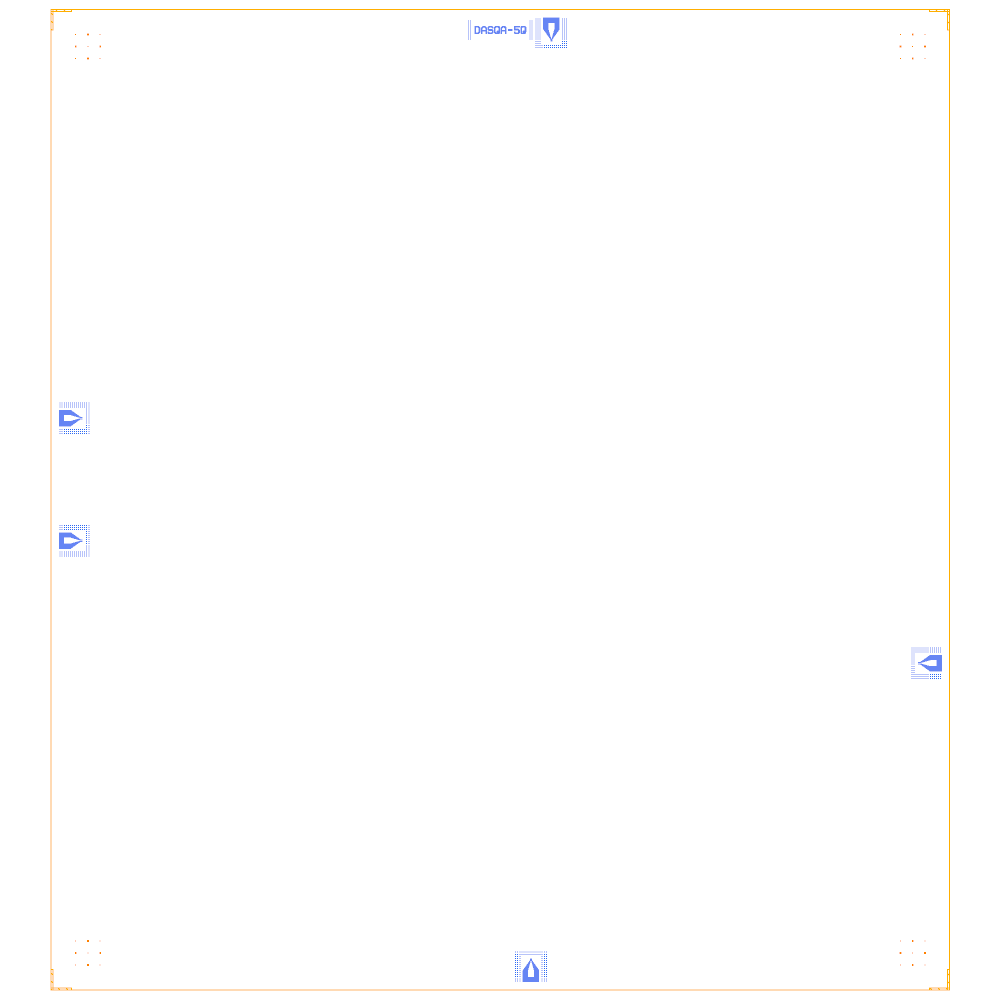

**On the chip so far:** 5 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 5 component(s) `Launch_Readout_0`, `Launch_Readout_1`, `Launch_Readout_2`, `Launch_Readout_3`, `Launch_Readout_4`.

WindowsPath('examples/designs/community/mqt_dasqa_s2_pads.png')

In [6]:
with d.batch():
    lp = {0: d.add("Launch_Readout_0", "metal:LaunchpadWirebond", at=(10500, 4000), rot=180, edge="e"),
          1: d.add("Launch_Readout_1", "metal:LaunchpadWirebond", at=P(3625, 8000), rot=-90, edge="n"),
          2: d.add("Launch_Readout_2", "metal:LaunchpadWirebond", at=P(3375, -2000), rot=90, edge="s"),
          3: d.add("Launch_Readout_3", "metal:LaunchpadWirebond", at=P(-1750, 3000), rot=0, edge="w"),
          4: d.add("Launch_Readout_4", "metal:LaunchpadWirebond", at=(500, 7000), rot=0, edge="w")}
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "mqt_dasqa_s2_pads.png", size=(1000, 1000), width=360)

## Design 3 · Readout line: the series capacitors and their pad lines

Each qubit is read out through its own `CapNInterdigital` (Metal's defaults: five 20 µm fingers, 6 µm gaps), a series
capacitor between the readout resonator and the line to the launchpad. The capacitors sit where the mapper puts them:
1600 µm below or above the south and north qubits (orientation 0, here on the pin axis as the pads), and 1450 µm west
of the qubit for the middle row (orientation −90, `north_end` towards the qubit). No qubit is needed for
them, so they come first, with their lines (`TL_Readout_k`, PDK CPW 10/6 µm):
- `Q_1`, `Q_2` and `Q_3`: a straight from the capacitor to its pad, as in the source (longer or shorter now that the pads
  are at the edge);
- `Q_4`: west from the capacitor, north to y = 7000 µm and west again to its pad, past `Q_3`'s pocket;
- `Q_0`: west from the capacitor, south to y = 4000 µm and east below `Q_0` to its pad.

capacitor ports: ['north_end', 'south_end']
{'TL_Readout_0': 4533.2, 'TL_Readout_1': 1515.0, 'TL_Readout_2': 369.0, 'TL_Readout_3': 519.0, 'TL_Readout_4': 5433.2}


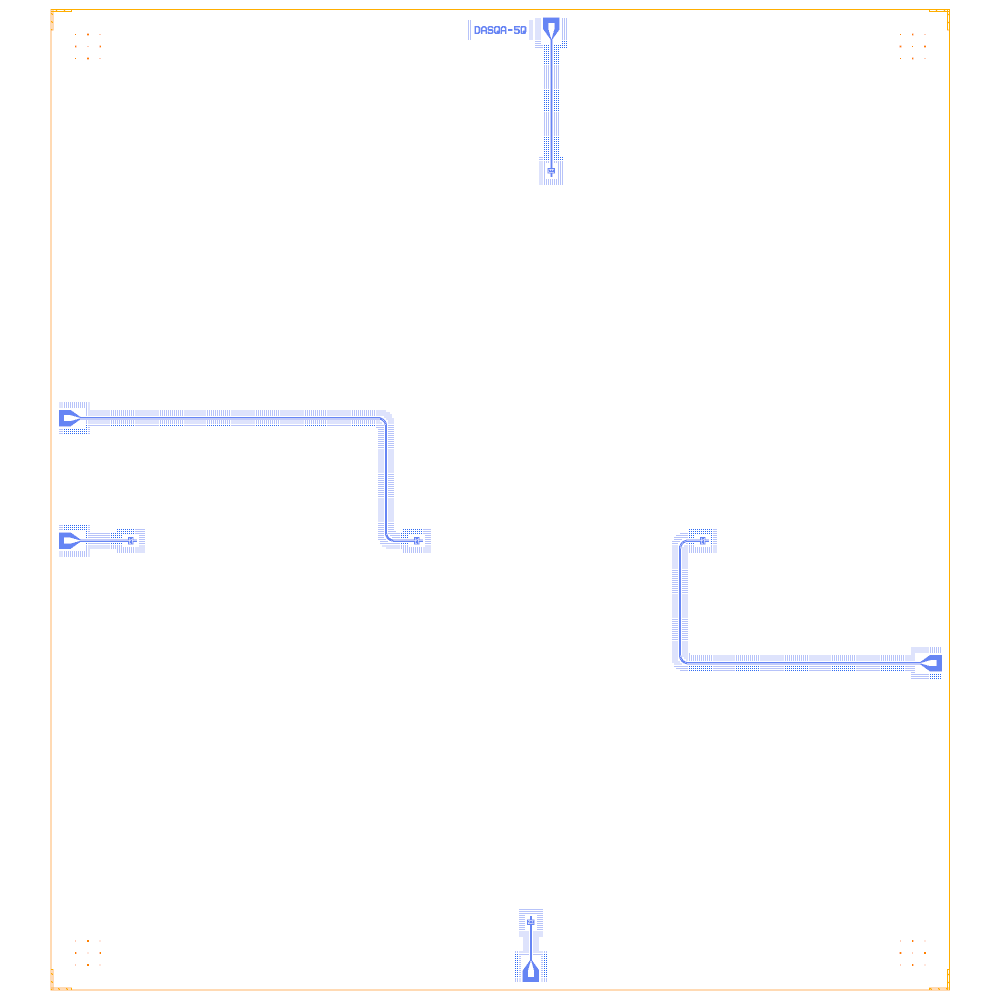

**On the chip so far:** 5 pads · 0 qubits · 5 other components · 5 routes · 0 declared couplings. **This step added** 5 component(s) `Cap_Readout_0`, `Cap_Readout_1`, `Cap_Readout_2`, `Cap_Readout_3`, `Cap_Readout_4` and 5 route(s) `TL_Readout_0`, `TL_Readout_1`, `TL_Readout_2`, `TL_Readout_3`, `TL_Readout_4`.

WindowsPath('examples/designs/community/mqt_dasqa_s3_readout_line.png')

In [7]:
CAP = {0: (P(5550, 3000), -90), 1: (P(3625, 7600), 0), 2: (P(3375, -1600), 0), 3: (P(-1450, 3000), -90),
       4: (P(2050, 3000), -90)}                  # mapper positions (Q_1 / Q_2 on the pin axis), orientations
with d.batch():
    cap = {k: d.add(f"Cap_Readout_{k}", "metal:CapNInterdigital", at=at, rot=rot) for k, (at, rot) in CAP.items()}
    d.route("TL_Readout_0", cap[0].south_end, lp[0].tie, nodes=[(7700, 5500), (7700, 4000)])
    d.route("TL_Readout_1", cap[1].north_end, lp[1].tie)
    d.route("TL_Readout_2", cap[2].south_end, lp[2].tie)
    d.route("TL_Readout_3", cap[3].south_end, lp[3].tie)
    d.route("TL_Readout_4", cap[4].south_end, lp[4].tie, nodes=[(4100, 5500), (4100, 7000)])
rebuild(d)
print("capacitor ports:", sorted(cap[0].ports))
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "mqt_dasqa_s3_readout_line.png", size=(1000, 1000), width=360)

## Design 4 · Qubit placement: five pocket transmons with trilayer junctions

**The frequency plan (this rebuild's choice).** DASQA's frequency generator puts the centre qubit at the middle of its
band, (5.00 + 5.34) / 2 = 5.17 GHz, and picks each neighbour by a Monte-Carlo yield search against its collision rules
(neighbours at least 17 MHz apart, not 170 or 340 MHz apart, with α = −340 MHz). That search is not run here; the
rebuild takes `Q_4` = 5.17 GHz and puts the four neighbours at 5.04, 5.10, 5.24 and 5.30 GHz, inside the band and clear
of those rules.

**Junction sizing.** The optimiser would reach f_q by changing the pocket's `pad_gap` and `pad_height` through its
regression models; the rebuild leaves the pocket at Metal's defaults (pads 455 × 90 µm, 30 µm gap, 650 µm pocket) and
sizes the Quantcore trilayer junction instead: `size_junction(f_q, C_Σ)` solves the junction on the PDK rule for each
qubit's C_Σ (without the junction; from this design's LOM with a 14 nH probe junction: `Q_4` carries five connection
pads and the most capacitance), and `trilayer_junction(..., lj_nH=)` draws it and returns the L_J and C_J the LOM uses.

At these C_Σ a 5.0–5.3 GHz qubit needs E_J/h ≈ 10.7–13.2 GHz, so R_n comes out 82–102 kΩ, **outside the PDK window of
40–50 kΩ** (the table says which). Following the project rule (values are flagged, never retuned), the plan stays and
the DRC reports `pdk_rn`. The PDK finger grid draws `Q_2` and `Q_3` with the same junction. The source's
`config.yml` also asks for E_C/E_J = 50, a ratio the optimiser has no model for; these pockets give E_J/E_C ≈ 32–47.

In [8]:
F_Q = {"Q_0": 5.04, "Q_1": 5.10, "Q_2": 5.24, "Q_3": 5.30, "Q_4": 5.17}    # GHz, this rebuild's plan (Q_4: the generator's)
C_SIGMA = {"Q_0": 50.9, "Q_1": 54.3, "Q_2": 54.3, "Q_3": 52.1, "Q_4": 60.9}  # fF without C_J: this design's LOM, 14 nH probe
SIZING = {q: size_junction(F_Q[q], c, c_includes_junction=False) for q, c in C_SIGMA.items()}
display(Markdown(sizing_md(SIZING)))

| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |
|---|---|---|---|---|---|---|
| Q_0 | 5.040 | 57.5 | 15.23 | 101.8 | 5.028 | no |
| Q_1 | 5.100 | 61.5 | 14.05 | 93.9 | 5.103 | no |
| Q_2 | 5.240 | 61.9 | 13.27 | 88.7 | 5.203 | no |
| Q_3 | 5.300 | 59.6 | 13.43 | 89.7 | 5.292 | no |
| Q_4 | 5.170 | 69.1 | 12.34 | 82.5 | 5.145 | no |

**The qubits.** The mapper's pockets at (3500·x, 3000·y) µm on its grid, orientation −90, with the connection pads it
keeps for this plus (`B0` … `B4` are the Metal pin names; with orientation −90, `loc_W`/`loc_H` = (−1, −1) is the top-left
corner, (−1, +1) top-right, (+1, −1) bottom-left, (+1, +1) bottom-right and `B4` = (0, −1) the west side):
- `Q_4`: all five, `B0`/`B2` to the north and south buses on its west side, `B1`/`B3` to the east and south ones, `B4` its
  readout;
- `Q_3`: `B3` (bus) and `B4` (readout); `Q_0`: `B0` (bus) and `B4` (readout);
- `Q_2`: `B1` (bus) and `B2` (readout); `Q_1`: `B2` (bus) and `B1` (readout).

The second picture zooms on `Q_4` with its five pads.

<metal:TransmonPocket6 Q_4 ports=['B0', 'B1', 'B2', 'B3', 'B4', 'squid_a', 'squid_b']>


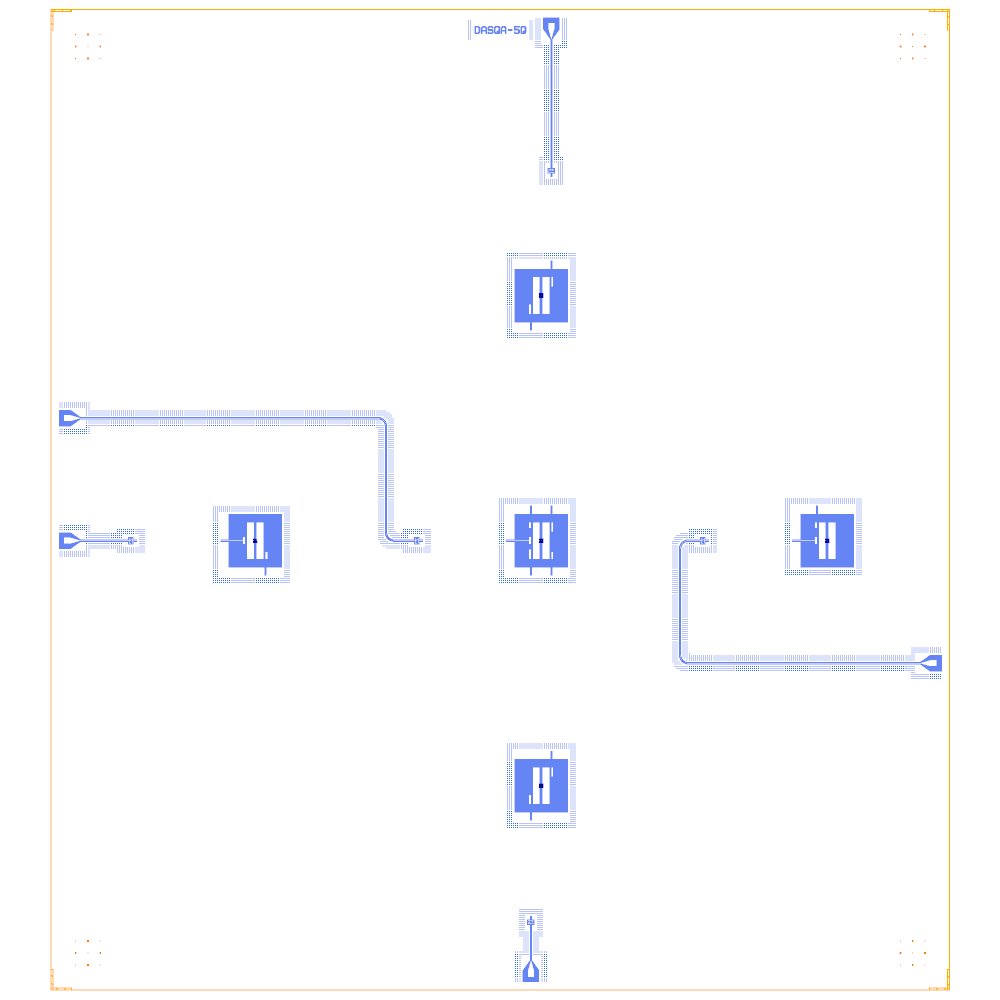

**On the chip so far:** 5 pads · 5 qubits · 5 other components · 5 routes · 0 declared couplings. **This step added** 5 component(s) `Q_0`, `Q_1`, `Q_2`, `Q_3`, `Q_4`.

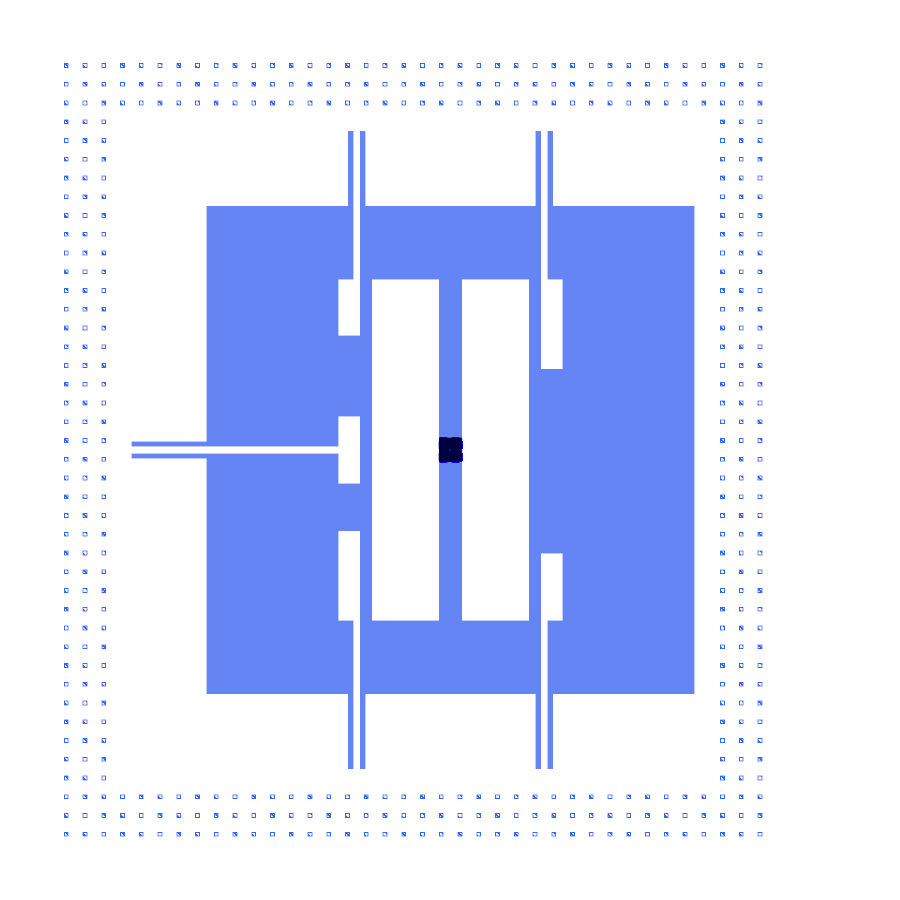

WindowsPath('examples/designs/community/mqt_dasqa_q4.png')

In [9]:
PAD = dict(B0=dict(loc_W=-1, loc_H=-1, pad_width=75), B1=dict(loc_W=-1, loc_H=1, pad_width=120),
           B2=dict(loc_W=1, loc_H=-1, pad_width=120), B3=dict(loc_W=1, loc_H=1, pad_width=90),
           B4=dict(loc_W=0, loc_H=-1, pad_width=90))                     # the mapper's connection pads
QUBITS = {"Q_0": ((7000, 3000), ["B0", "B4"]), "Q_1": ((3500, 6000), ["B1", "B2"]),
          "Q_2": ((3500, 0), ["B1", "B2"]), "Q_3": ((0, 3000), ["B3", "B4"]),
          "Q_4": ((3500, 3000), ["B0", "B1", "B2", "B3", "B4"])}         # source µm, the pads the mapper keeps
q = {}
with d.batch():
    for name, (xy, pads) in QUBITS.items():
        params, jj = trilayer_junction("metal:TransmonPocket6", lj_nH=SIZING[name].lj_nH)
        q[name] = d.add(name, "metal:TransmonPocket6", at=P(*xy), rot=-90, junction=jj,
                        connection_pads={p: PAD[p] for p in pads}, **params)
print(q["Q_4"])
layout_step(d, OUT / "mqt_dasqa_s4_qubits.png", size=(1000, 1000), width=360)
qx, qy = P(3500, 3000)
snap(d, OUT / "mqt_dasqa_q4.png", box=(qx - 600, qy - 600, qx + 600, qy + 600), size=(900, 900), width=360)

## Design 5 · Readout: five λ/2 readout meanders

In the source the line between a qubit's readout pad and its capacitor is a short `RoutePathfinder` path (about 1–2 mm)
with no length or frequency: the generator leaves the readout to its optimiser, whose resonator step does nothing.
**This rebuild's choice:** each `Readout_k` is a λ/2 meander (capacitive at both ends: the pocket's pad and the series
capacitor) at 6.6 / 6.8 / 7.0 / 7.2 / 7.4 GHz for `Q_0` … `Q_4`, 200 MHz apart and 1.5–2.2 GHz above the qubits.

The lengths are v_ph / 2f of the PDK's 10/6 µm CPW on sapphire (`tl_resonator`), minus 4.8 % for the loading of the
pad and the capacitor seen in this design's LOM. Each meander fills the 1.0–1.2 mm straight between the qubit's pin and
its capacitor (50 µm bends; the source's 90 µm fillet would need a longer straight).

readout lengths (µm): {0: 9089.8, 1: 8822.4, 2: 8570.3, 3: 8332.3, 4: 8107.1}


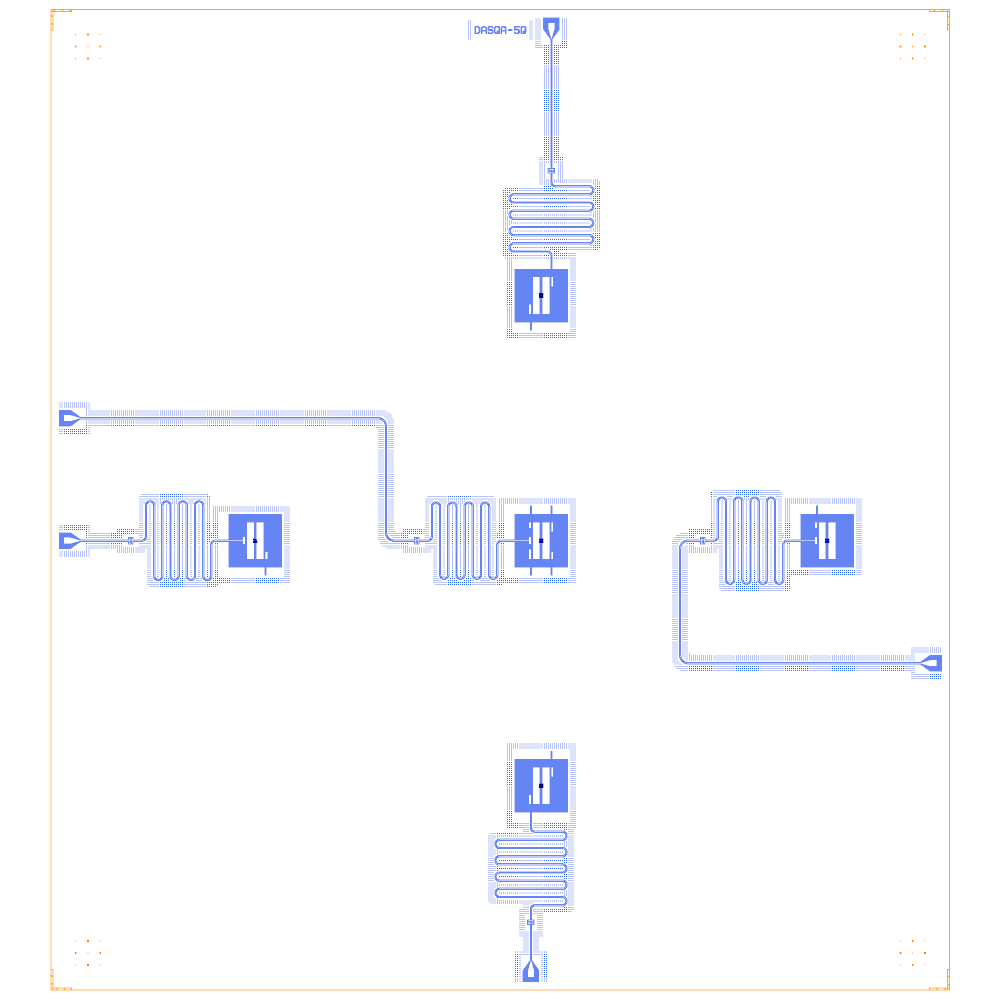

**On the chip so far:** 5 pads · 5 qubits · 5 other components · 10 routes · 0 declared couplings. **This step added** 5 route(s) `Readout_0`, `Readout_1`, `Readout_2`, `Readout_3`, `Readout_4`.

WindowsPath('examples/designs/community/mqt_dasqa_s5_readouts.png')

In [10]:
F_R = {0: 6.6, 1: 6.8, 2: 7.0, 3: 7.2, 4: 7.4}   # GHz, this rebuild's plan for Readout_0 … Readout_4
VP = tl_resonator(4500, 10, 6)["vp_m_s"]          # PDK stack (sapphire): phase velocity of the 10/6 µm CPW
L_RO = {k: round(VP / (2 * f * 1e9) * 1e6 * 0.952, 1) for k, f in F_R.items()}   # λ/2, −4.8 %: pad + IDC loading (LOM)
PIN = {0: "B4", 1: "B1", 2: "B2", 3: "B4", 4: "B4"}                             # each qubit's readout pad
with d.batch():
    for k, pin in PIN.items():
        end = cap[k].south_end if k == 1 else cap[k].north_end                  # the capacitor end facing the qubit
        d.route(f"Readout_{k}", getattr(q[f"Q_{k}"], pin), end, meander=L_RO[k], r=50)
print("readout lengths (µm):", L_RO)
layout_step(d, OUT / "mqt_dasqa_s5_readouts.png", size=(1000, 1000), width=360)

## Design 6 · Coupling: four buses from the centre qubit

The mapper joins each pair of grid neighbours with a `RouteMeander` (99 µm fillet). "Sideways" buses (`CS_a_b`) run
between the lower or upper corner pads of two qubits on a row, "upward" ones (`CU_a_b`) between the corner pads of two
qubits on a column, with the meander pushed 700 µm to one side (`asymmetry`). In the source a bus is as long as the
generator's estimate, λ_g/2 at the frequency of the first qubit of the pair on its silicon stack (`bus_length`, the same
call with the same inputs): 11283 µm for `CS_3_4` (`Q_3`, 5.30 GHz), 11412 µm for `CU_2_4` (`Q_2`, 5.24 GHz) and
11566 µm for `CU_4_1` and `CS_4_0` (`Q_4`, 5.17 GHz). On sapphire, loaded by the connection pads, those lengths put each
bus at 5.16–5.27 GHz, on the qubits it joins, so bus and qubits hybridise (LOM 3 puts one back to show it).

**This rebuild's choice:** dispersive buses at 6.30 GHz (`CS_3_4`), 6.15 GHz (`CU_2_4`), 6.00 GHz (`CU_4_1`) and
5.85 GHz (`CS_4_0`): 0.55–1.25 GHz above the qubits, at least 300 MHz below the lowest readout (6.6 GHz) and 150 MHz
apart, since all four meet at `Q_4`. The lengths are v_ph / 2f of the PDK's 10/6 µm CPW on sapphire with a per-bus
factor of 0.944–0.951 for the loading of the two connection pads (seen in this design's LOM).

The routes are qcc meanders on waypoints: `CS_3_4` below the axis, `CS_4_0` above it, `CU_2_4` offset 650 µm to the
east and `CU_4_1` 650 µm to the west (the source's asymmetry), each with one KQC `Meander` on its longest straight.

bus lengths (µm): {'CS_3_4': 9442.6, 'CU_2_4': 9697.5, 'CU_4_1': 9969.3, 'CS_4_0': 10244.3}
the generator's rule (µm): {'CS_3_4': 11282.6, 'CU_2_4': 11411.8, 'CU_4_1': 11566.3, 'CS_4_0': 11566.3}


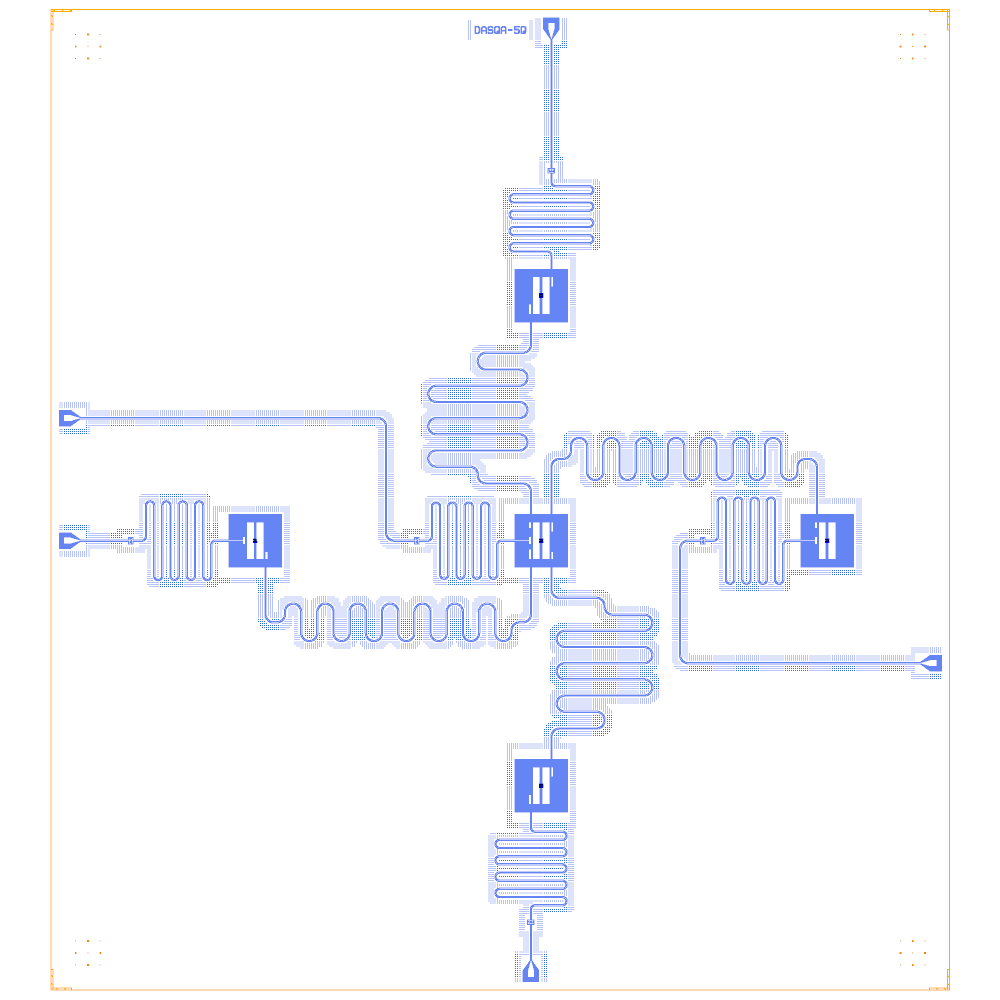

**On the chip so far:** 5 pads · 5 qubits · 5 other components · 14 routes · 0 declared couplings. **This step added** 4 route(s) `CS_3_4`, `CS_4_0`, `CU_2_4`, `CU_4_1`.

WindowsPath('examples/designs/community/mqt_dasqa_s6_buses.png')

In [11]:
F_BUS = {"CS_3_4": 6.30, "CU_2_4": 6.15, "CU_4_1": 6.00, "CS_4_0": 5.85}        # GHz, this rebuild's dispersive plan
K_BUS = {"CS_3_4": 0.944, "CU_2_4": 0.9464, "CU_4_1": 0.9492, "CS_4_0": 0.951}   # pad loading, from this design's LOM
L_BUS = {b: round(VP / (2 * f * 1e9) * 1e6 * K_BUS[b], 1) for b, f in F_BUS.items()}
L_GEN = {"CS_3_4": bus_length(F_Q["Q_3"]), "CU_2_4": bus_length(F_Q["Q_2"]),
         "CU_4_1": bus_length(F_Q["Q_4"]), "CS_4_0": bus_length(F_Q["Q_4"])}   # the generator's rule (LOM 3)
R = 99                                                                          # the mapper's fillet
with d.batch():
    d.route("CS_3_4", q["Q_3"].B3, q["Q_4"].B2, meander=L_BUS["CS_3_4"], r=R, nodes=[(2625, 4500), (5875, 4500)])
    d.route("CS_4_0", q["Q_4"].B1, q["Q_0"].B0, meander=L_BUS["CS_4_0"], r=R, nodes=[(6125, 6500), (9375, 6500)])
    d.route("CU_2_4", q["Q_2"].B1, q["Q_4"].B3, meander=L_BUS["CU_2_4"], r=R,
            nodes=[(6125, 3200), (6775, 3200), (6775, 4800), (6125, 4800)])
    d.route("CU_4_1", q["Q_4"].B0, q["Q_1"].B2, meander=L_BUS["CU_4_1"], r=R,
            nodes=[(5875, 6200), (5225, 6200), (5225, 7800), (5875, 7800)])
print("bus lengths (µm):", L_BUS)
print("the generator's rule (µm):", L_GEN)
layout_step(d, OUT / "mqt_dasqa_s6_buses.png", size=(1000, 1000), width=360)

## Design 7 · Control lines: none

The mapper draws no drive or flux lines: the pockets are fixed-frequency transmons, driven through their readouts.
Nothing is placed here.

## Design 8 · The whole chip: sim groups, targets, centring the core, save

**Sim groups:** each qubit with its readout meander and capacitor (`Q_0R` … `Q_4R`, the default analyses: eigenmode /
EPR and Q3D C-matrix), 50 µm margins so each box cuts the buses and the pad line once. **Targets:** the frequency plan of
Designs 4 to 6 (f_q, f_r and the bus frequencies).

**Centring the core.** The PDK wants the chip content in the middle of the die. The plus sits low and slightly west in
the 11 × 12 mm die, so `center_core` measures the core (qubits, capacitors, readouts and buses; the launchpads, pinned to
the edge, and the pad lines that run to them are left out) and shifts the whole design: instance positions and route
waypoints. The pads move along their edge with it and keep their 100 µm.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): when the segments are run again unchanged it says *same design*, so `git diff` stays empty.

After the whole chip, two zooms: the centre of the plus (`Q_4` with its four bus leads, its readout meander and
capacitor, and the start of its pad line) and `Q_3`'s readout chain (the pocket's `B4` pad, the meander, the
capacitor, the line to the west launchpad).

shift applied (µm): (135.5, 573.0)


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| Launch_Readout_0 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| Launch_Readout_1 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| Launch_Readout_2 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_Readout_3 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| Launch_Readout_4 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |

**Same design as before:** `examples/designs/community/mqt_dasqa.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer mqt_dasqa: 15 instances, 14 routes, live=False> → examples\designs\community\mqt_dasqa.json
{'TL_Readout_0': 4397.7, 'TL_Readout_1': 942.0, 'TL_Readout_2': 942.0, 'TL_Readout_3': 654.5, 'TL_Readout_4': 5568.7, 'Readout_0': 9089.8, 'Readout_1': 8822.4, 'Readout_2': 8570.3, 'Readout_3': 8332.3, 'Readout_4': 8107.1, 'CS_3_4': 9442.6, 'CS_4_0': 10244.3, 'CU_2_4': 9697.5, 'CU_4_1': 9969.3}


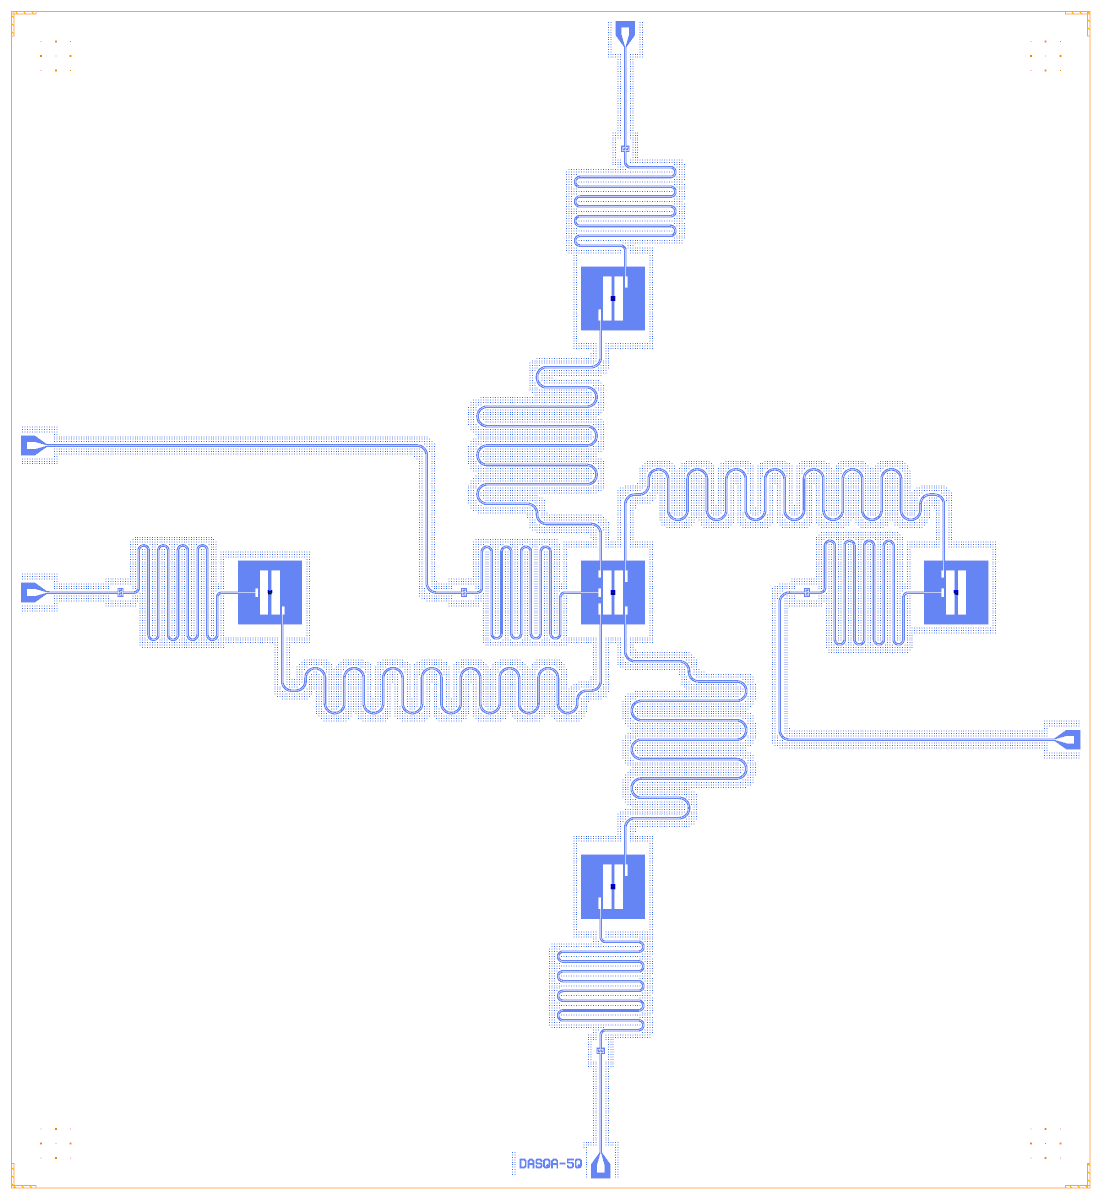

**On the chip so far:** 5 pads · 5 qubits · 5 other components · 14 routes · 0 declared couplings. **This step added** nothing new to the layout.

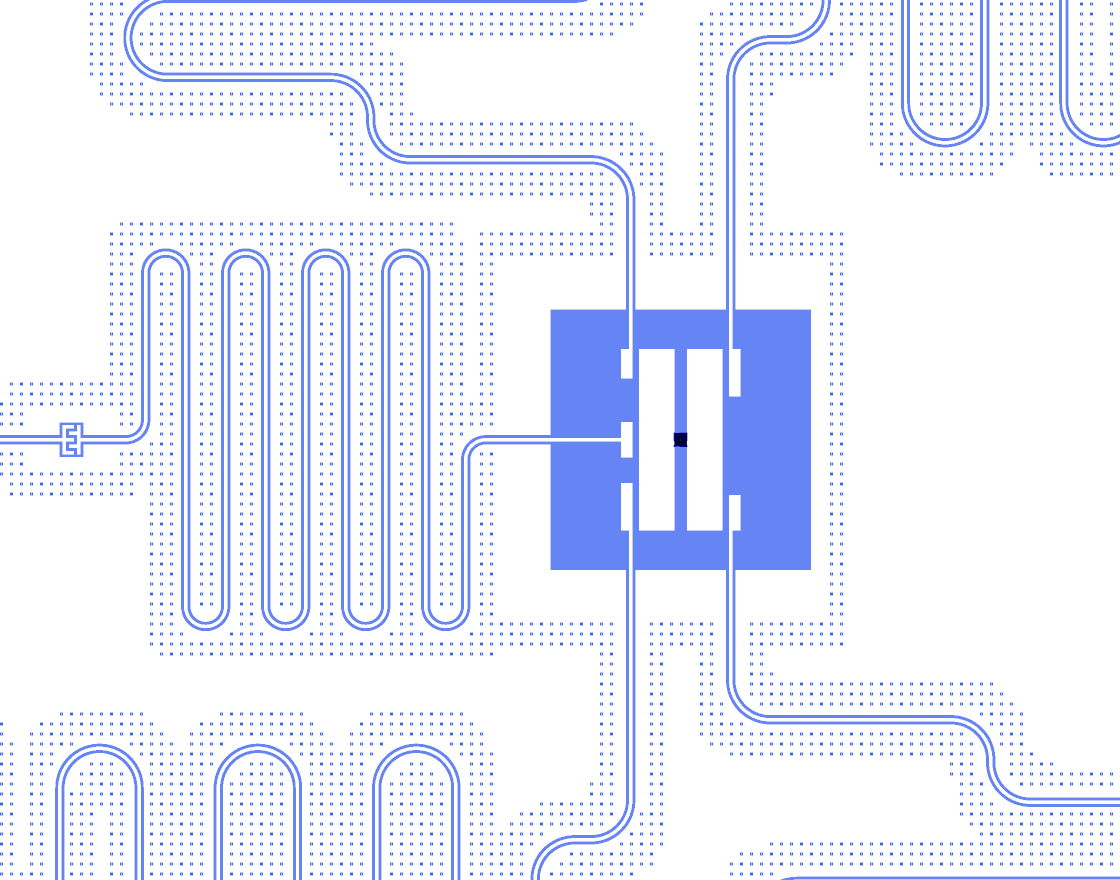

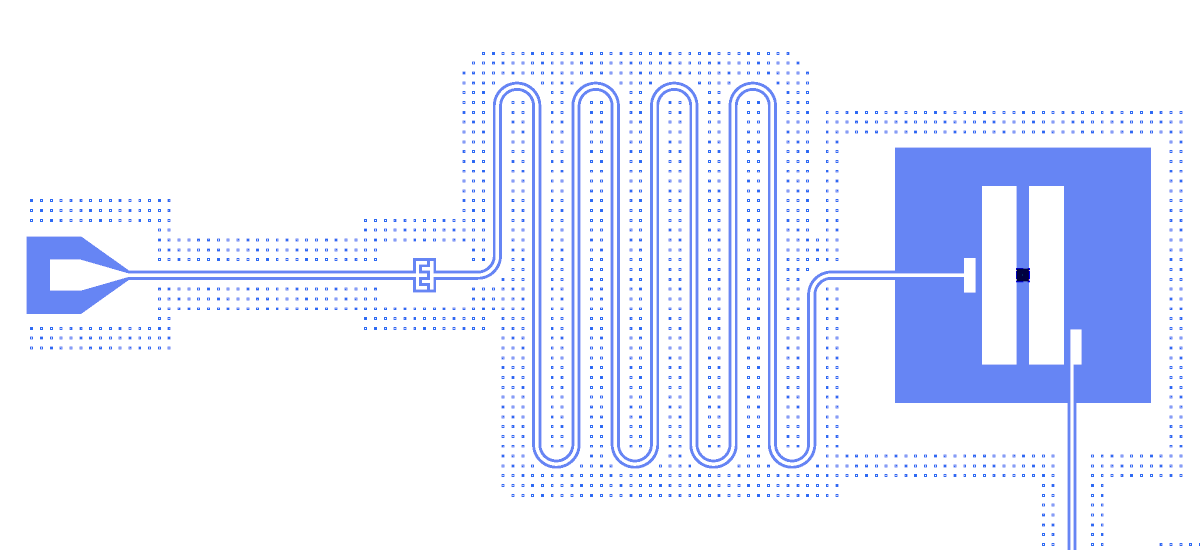

WindowsPath('examples/designs/community/mqt_dasqa_readout.png')

In [12]:
with d.batch():
    for k in range(5):
        d.sim_group(f"Q_{k}R", [f"Q_{k}", f"Readout_{k}", f"Cap_Readout_{k}"], margin_um=50)
    d.targets(**{n: {"f_q_GHz": f} for n, f in F_Q.items()}, **{f"Readout_{k}": {"f_GHz": f} for k, f in F_R.items()},
              **{b: {"f_GHz": f} for b, f in F_BUS.items()})
PADS = [f"Launch_Readout_{k}" for k in range(5)] + [f"TL_Readout_{k}" for k in range(5)]
shift = center_core(d, skip=PADS)
print("shift applied (µm):", shift)
rebuild(d)
display(Markdown(pads_md(d)))
DESIGN, same = save_design(d, OUT / "mqt_dasqa.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "mqt_dasqa_routes.png", size=(1100, 1200), width=420)
QX, QY = d.data["instances"]["Q_4"]["place"]["at"]          # after the centring
Q3X, Q3Y = d.data["instances"]["Q_3"]["place"]["at"]
snap(d, OUT / "mqt_dasqa_centre.png", box=(QX - 1700, QY - 1100, QX + 1100, QY + 1100), size=(1120, 880), width=480)
snap(d, OUT / "mqt_dasqa_readout.png", box=(Q3X - 2600, Q3Y - 700, Q3X + 450, Q3Y + 700), size=(1200, 550), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK
margins. There are three kinds of finding:
- **errors** would make the chip wrong (a short, a route through a component); there must be none;
- **warnings** are worth a look but can be intended: here the junction attachment points (`squid_a` / `squid_b` of the
  five pockets; the cell draws its own junction, nothing is routed there);
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced. Here: `pdk_rn` on the five junctions (the 5.0–5.3 GHz plan, Design 4).

Expected (from a run on 2026-11-19): **no errors**; 10 `dangling_port` warnings (`squid_a` / `squid_b` of the five
pockets); 5 `pdk_rn` (83.3–102.3 kΩ as drawn). No `pad_edge`: the five launchpads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks: cheese source, centring, junction types, design warnings. Its content centre
includes the edge pads and the long pad lines of `Q_0` and `Q_4`, which `center_core` leaves out: the core itself is
centred.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit:
- **qubits:** each pocket is a floating pair of pads with its trilayer junction, plus a node per connection pad (C_g
  to the near pad, C to the far one, C to ground);
- **readouts:** each `Readout_k` is a λ/2 `TLres` from the qubit's readout pad to the capacitor's inner end; the
  `CapNInterdigital` is a series C to the pad line, which ends in the launchpad's 50 Ω port;
- **buses:** each is a λ/2 `TLres` between the two corner pads it joins.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

First each qubit with its readout chain (meander, capacitor, pad line and launchpad: QuCat normal modes, then the
QuTiP dressed values), the plan's targets in brackets. Then each bus with the two qubits it joins (three modes), with
the static ZZ and the bus-mediated exchange coupling J (`exchange_coupling`: `Q_4`'s L_J is moved through the crossing
with its neighbour and the splitting is fitted). The junctions are sized for the plan from the LOM's own C_Σ and the readout lengths carry the LOM's
loading, so f_q and f_r should land within a fraction of a percent of their targets; the bus lengths carry the pads'
loading in the same way, so each bus mode should sit on its target, well clear of the qubits.

What the tables show (from a run on 2026-11-19):
- f_q 5.025–5.295 GHz, within 0.7 % of the plan (the PDK finger grid draws `Q_2` and `Q_3` alike);
- f_r 6.616–7.375 GHz, within 0.4 % of 6.6–7.4 GHz; κ 0.53–0.73 MHz through the series capacitors; χ −0.77 … −2.73 MHz;
- the bus modes at 5.850 / 6.000 / 6.150 / 6.300 GHz (`CS_4_0`, `CU_4_1`, `CU_2_4`, `CS_3_4`), on their targets and
  316 MHz or more below the lowest readout, bus participation 0.95–0.98; J 3.5–4.8 MHz, static ZZ +97 to +121 kHz;
- the linear modes of `Q_1`/`Q_4` and `Q_0`/`Q_4` lie within 20 MHz of each other and mix by 12–18 %, but their dressed
  f_q are 43 and 123 MHz apart and QuTiP does not flag them as hybridised.

In [ ]:
READ = {f"Q_{k}R": [f"Q_{k}", f"Readout_{k}", f"Cap_Readout_{k}", f"TL_Readout_{k}", f"Launch_Readout_{k}"]
        for k in range(5)}
res = simulate_groups(d, READ)
display(Markdown(groups_md(res, d.data["targets"])))
BUSES = {"CS_3_4": ["Q_3", "CS_3_4", "Q_4"], "CU_2_4": ["Q_2", "CU_2_4", "Q_4"],
         "CU_4_1": ["Q_4", "CU_4_1", "Q_1"], "CS_4_0": ["Q_4", "CS_4_0", "Q_0"]}
coupled = simulate_groups(d, BUSES, max_modes=3)
for g, r in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))
PAIR = {"CS_3_4": ("Q_3", "Q_4"), "CU_2_4": ("Q_2", "Q_4"), "CU_4_1": ("Q_1", "Q_4"), "CS_4_0": ("Q_0", "Q_4")}
J = {f"{a}–{b} ({bus})": exchange_coupling(d, BUSES[bus], a, b) for bus, (a, b) in PAIR.items()}
display(Markdown("**Bus-mediated exchange coupling J (avoided crossing):**\n\n" + exchange_md(J)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators: the readouts and, in the bus groups, the buses; filled markers are the QuTiP dressed values; red bars the
targets), (b) the dispersive shift |χ| of each readout.

In [ ]:
plot_lom({**res, **coupled}, OUT / "mqt_dasqa_lom.png", targets=d.data["targets"],
         title="mqt_dasqa: LOM per readout chain and per bus")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The LOM is cheap, so a design change can be checked in seconds. Here `CS_3_4`
goes back to the generator's own length (`bus_length(F_Q["Q_3"])`, 11283 µm against this rebuild's 9444 µm) in a copy,
to see what the source's rule does on this stack: the bus falls onto the qubits, takes part of `Q_4`'s junction
participation, and the static ZZ between `Q_3` and `Q_4` grows by two orders of magnitude. From a run on 2026-11-19:
the bus mode falls from 6.300 to 5.270 GHz (its own participation from 0.98 to 0.83, with 0.15 of `Q_4`'s junction in
it) and the static ZZ goes from +97 kHz to −10.8 MHz. `design_copy` opens a second, non-live Designer on the saved
design, so the design file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
d2["CS_3_4"].set(meander=L_GEN["CS_3_4"])                                       # the generator's length
gen = simulate_groups(d2, {"CS_3_4": BUSES["CS_3_4"]}, max_modes=3)
display(Markdown(f"**CS_3_4 at the generator's {L_GEN['CS_3_4']:.0f} µm, QuCat normal modes:**\n\n"
                 + modes_md(gen["CS_3_4"])))
display(Markdown("**Static ZZ (QuTiP), this rebuild's length and the generator's:**\n\n"
                 + zz_md({f"CS_3_4 ({L_BUS['CS_3_4']:.0f} µm)": coupled["CS_3_4"],
                          f"CS_3_4 ({L_GEN['CS_3_4']:.0f} µm)": gen["CS_3_4"]})))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/community/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The five sim groups (each qubit with its readout meander and capacitor) are exported as Q3D C-matrix jobs
(capacitances by net name), and `Q_3R` also as an eigenmode/EPR job: `Q_3` is the qubit with one bus, so its box cuts the
fewest lines (`CS_3_4` and the pad line). The job folders are self-contained (`build/jobs/<design>_<group>_<analysis>`);
exporting again replaces a folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the
top) picks the fast test settings for every job exported from here on. With `RUN_FEM = True` the next cells solve each
Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an AEDT window you have open is never touched.
On another machine: `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/community/fem/: solved results are kept here
GROUPS = [f"Q_{k}R" for k in range(5)]
jobs = export_sims(DESIGN, GROUPS, analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, ["Q_3R"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each qubit with its readout chain: the pocket's two pads, its connection pads, the readout meander,
the capacitor's fingers and the lines the box cuts, as named nets. Each net is named after its LOM node, so the matrix
goes straight into the circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results,
else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q_3R` box in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet, and the pad line and the bus the box cuts end
in 50 Ω there, so each mode's Q is that loading. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh** itself
to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group and
box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before
the eigenmode is solved) and a fast sweep around it. The box cuts two lines (the pad line and `CS_3_4`), so the job has
two ports; the readout is a series resonance between them, seen in S21 as a peak, not a hanger notch.

In [ ]:
f_r0 = res["Q_3R"].params.get("Readout_3.f_GHz")      # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q_3R", jobs_eig["Q_3R"][0], keep_eig["Q_3R"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q_3R"]:
    display(Markdown(driven_md(keep_drv["Q_3R"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {"Q_3R": ("Q_3", "Readout_3", "Q_3R")}   # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = res[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "mqt_dasqa_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: the qubit's mode is the one its junction participates in most, the readout's the
remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms, κ = f/Q of the
50 Ω-terminated box. The driven run adds its S21 values where it finds a resonance.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q_3R"]:
    qb, rr, _ = PAIRS["Q_3R"]
    fem_values.setdefault("Q_3R", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q_3R"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of Q_3 and f_r, χ, κ of "
          "Readout_3 from pyEPR (κ = f/Q through the series capacitor and the pad line).")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of each group's components by its job's C-matrix
values (matched by net name; the other branches keep their estimates) and the same LOM runs again: f_q, α, f_r, χ and κ
of each qubit with its readout. **FEM directly:** `Q_3`'s eigenmode values (Results 2). The left column is the LOM on the
component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for k in range(5):
    qb, rr, g = f"Q_{k}", f"Readout_{k}", f"Q_{k}R"
    lom_p = res[g].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=READ[g]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(key, lom_p.get(key), on_fem.get(key), f"{g}: LOM on the Q3D C-matrix") for key in keys]
    rows += [(key, lom_p.get(key), fem_values[g][key], f"{g}: eigenmode + pyEPR") for key in keys
             if key in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on each group's Q3D C-matrix and next to Q_3's eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the plan

The design carries the frequency plan as its targets (Design 8: f_q 5.04–5.30 GHz, f_r 6.6–7.4 GHz).
`target_copy(DESIGN, {})` writes the design with them (nothing added) to `build/mqt_dasqa_target.json`, and the
feedback works on that copy.

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the circuit
(on the Q3D values where a solve was kept) and picks one value per quantity (the consensus). `loop.feedback` anchors
a surrogate on that point and proposes the knobs that put the targets inside their tolerances: L_J for f_q, the readout
meander's length for f_r. The proposal is written as revision 1, built and netlist-checked. The buses are not
qubit–readout pairs, so the feedback does not tune them (their targets stay for the LOM tables; LOM 3 is the by-hand
step for them).

**No PDK L_J bounds:** the junctions are already outside the 40–50 kΩ window (Design 4), so `pdk_lj_bounds` would pull
every L_J into it and the qubits to about 7 GHz, away from the plan. The feedback runs on its own bounds and the DRC keeps
flagging `pdk_rn`. The revision changes the LOM's L_J; to draw it, size the finger with
`trilayer_junction("metal:TransmonPocket6", lj_nH=...)`, as Design 4 does.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (the plan), nothing added
BOUNDS = None                                    # not pdk_lj_bounds(DESIGN): the junctions are outside the window
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision, check it against the targets, feed back again for the next revision,
until every target is inside its tolerance or `MAX_ITER` revisions are made (`build/mqt_dasqa/revisions/`). Without
`RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's five Q3D jobs are exported and solved
first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D jobs (the five qubit boxes), exported to build/jobs/rev<k>/ and solved."""
    jobs_k = export_sims(rev, GROUPS, root=f"build/jobs/rev{k}")
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "mqt_dasqa_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `save_design(...)` wrote `examples/designs/community/mqt_dasqa.json` (Design 8): the whole design
  (cells, positions, routes, targets, sim groups); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (here the PDK band: the source has no GDS export and so no cheese of its own). The table lists each fab
  layer.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (this chip has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/mqt_dasqa.json` (layout + sidecar),
  `qcc design drc …`, `qcc mask …` (fab file), `qcc sim build … -g Q_3R -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

## Fab 2 · Snapshots

The full die (compare the README image: the plus, the four bus meanders, a readout chain per qubit), the centre qubit
with its five pads, its trilayer junction, `Q_3`'s readout chain, and the fab mask (Fab 1) round `Q_3`: the PDK band's
5 µm holes along the 3/0 keep-outs (holes on 1/0 and 3/0), the pocket's filled 3/0 box and the junction layers. Positions
are read from the design (after the centring shift).

In [ ]:
QX, QY = d.data["instances"]["Q_4"]["place"]["at"]
Q3X, Q3Y = d.data["instances"]["Q_3"]["place"]["at"]
show_snapshot(d, OUT / "mqt_dasqa.png", size=(1500, 1600))
show_snapshot(d, OUT / "mqt_dasqa_q4_fab.png", box=(QX - 600, QY - 600, QX + 600, QY + 600), width=420)
show_snapshot(d, OUT / "mqt_dasqa_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
show_snapshot(d, OUT / "mqt_dasqa_readout_chain.png", box=(Q3X - 2500, Q3Y - 700, Q3X + 500, Q3Y + 700),
              size=(1200, 560), width=480)
snap_file(Path("build") / "mqt_dasqa_fab.oas", OUT / "mqt_dasqa_cheese.png",
          box=(Q3X - 600, Q3Y - 600, Q3X + 600, Q3Y + 600), size=(1000, 1000), width=400);

## Summary

- **Matches the source:** the plus of five `TransmonPocket6` pockets with the mapper's positions, orientation and
  connection pads; the four buses on the same pins with the source's fillet; per qubit the same
  readout chain (pad, line, `CapNInterdigital`, line, `LaunchpadWirebond`), capacitors at the mapper's positions.
- **This rebuild's choices** (left open by the generator): the qubit frequencies 5.04 / 5.10 / 5.24 / 5.30 GHz around the
  generator's 5.17 GHz centre qubit, the readouts as λ/2 meanders at 6.6–7.4 GHz, and dispersive buses at
  5.85–6.30 GHz in place of the generator's bus lengths.
- **Changed by the PDK:** the 11 × 12 mm die and frame, sapphire, trilayer junctions sized for the plan (in place of
  the optimiser's pocket tuning), the five launchpads 100 µm from the die edge (`Q_4`'s and `Q_0`'s brought out of the
  plus), the core centred in the die, the PDK band cheese.
- **Open PDK design warnings:** `pdk_rn` on all five junctions (82–102 kΩ for 5.0–5.3 GHz on these pockets; flagged,
  not retuned).
- **What the LOM says about the source's rule:** a bus of λ/2 at the qubit frequency sits on the qubits on this
  stack, so bus and qubits hybridise and the static ZZ is in the MHz range (LOM 3); the dispersive buses keep it near
  100 kHz (LOM 1).
- **Feedback:** towards the plan on a copy: `loop.analyse`, `loop.feedback`, revisions until on target (LOM; FEM with
  `RUN_FEM`); no PDK L_J bounds (the junctions are outside the window).
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True`
  to fill the Simulate and Results cells.